# PRCP-1003 — Customer Transaction Prediction

**Domain:** Banking

**Problem statement:** Identify which customers will make a specific transaction in the future,
irrespective of the amount of money transacted.

- **Task 1:** Prepare a complete data analysis report on the given data.
- **Task 2:** Create a predictive model that helps the bank identify which customers will make a transaction in the future.
- **Model Comparison Report:** Compare several models and recommend the best one for production.
- **Report on Challenges Faced:** Describe the challenges in the data and the techniques used to handle them, with reasons.

**Dataset:** 200,000 customers × 202 columns: `ID_code`, `target` (0 = no transaction, 1 = transaction)
and 200 anonymized numeric features `var_0` … `var_199`.

### Project workflow
```
CUSTOMER TRANSACTION DATASET
  → 1. Load dataset → 2. Understand dataset
  → 3. EDA (missing values, duplicates, distributions, outliers, correlation)
  → 4. Preprocessing (clean data, encode, scale, split X / y)
  → 5. Algorithm selection → 6. Train multiple models → 7. Evaluate models
  → 8. Cross-validation → 9. Hyperparameter tuning → 10. Select best model
  → 11. Save model → 12. Prediction → 13. Deployment / API → 14. Final report
```

### Model strategy
```
Logistic Regression (baseline) → Random Forest → XGBoost
  → Compare performance → Best algorithm → Hyperparameter tuning → Final model
```

## Step 1 — Import libraries

In [1]:
import json
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold,
                                     cross_val_predict, cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)

RANDOM_STATE = 42

ROOT = Path(".")
RAW_PATH = ROOT / "data" / "raw" / "customer_transaction.csv"
PROCESSED_PATH = ROOT / "data" / "processed" / "processed_data.csv"
MODEL_PATH = ROOT / "models" / "customer_transaction_model.pkl"
FIG_DIR = ROOT / "reports" / "figures"
REPORT_PATH = ROOT / "reports" / "Customer_Transaction_Report.pdf"
for folder in [RAW_PATH.parent, PROCESSED_PATH.parent, MODEL_PATH.parent, FIG_DIR, ROOT / "deployment"]:
    folder.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, RED, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#8a8984"
CLASS_COLORS = {0: BLUE, 1: ORANGE}
MODEL_COLORS = {"Logistic Regression": BLUE, "Random Forest": ORANGE, "XGBoost": AQUA}
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, "#f2f2f0", RED])
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#c9c8c3", "grid.color": "#ecebe7",
                                    "axes.titleweight": "bold", "figure.dpi": 110})

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

print("Libraries imported")

Libraries imported


## Step 2 — Load the dataset

In [2]:
df = pd.read_csv("data/raw/customer_transaction.csv")
df.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,var_8,var_9,var_10,var_11,var_12,...,var_185,var_186,var_187,var_188,var_189,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,-4.9200,5.7470,2.9252,3.1821,14.0137,...,5.8764,11.8411,-19.7159,17.5743,0.5857,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,3.1468,8.0851,-0.4032,8.0585,14.0239,...,-4.8622,7.6543,-15.9319,13.3175,-0.3566,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,-4.9193,5.9525,-0.3249,-11.2648,14.1929,...,-5.3000,5.3745,-6.2660,10.1934,-0.8417,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,-5.8609,8.2450,2.3061,2.8102,13.8463,...,-0.0498,7.9336,-12.8279,12.4124,1.8489,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,6.2654,7.6784,-9.4458,-12.1419,13.8481,...,-7.8931,6.4209,5.9270,16.0201,-0.2829,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


## Step 3 — Understand the dataset

In [3]:
print("Shape            :", df.shape)
print("Rows (customers) :", f"{df.shape[0]:,}")
print("Columns          :", df.shape[1])
print("Memory usage     :", f"{df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

Shape            : (200000, 202)
Rows (customers) : 200,000
Columns          : 202
Memory usage     : 318.2 MB


In [4]:
df.info(verbose=False)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Columns: 202 entries, ID_code to var_199
dtypes: float64(200), int64(1), object(1)
memory usage: 308.2+ MB


In [5]:
df.dtypes.value_counts()

float64    200
object       1
int64        1
Name: count, dtype: int64

In [6]:
df.describe().T.head(15)

,count,mean,std,min,25%,50%,75%,max
target,200000.0,0.100490,0.300653,0.0000,0.000000,0.00000,0.000000,1.0000
var_0,200000.0,10.679914,3.040051,0.4084,8.453850,10.52475,12.758200,20.3150
var_1,200000.0,-1.627622,4.050044,-15.0434,-4.740025,-1.60805,1.358625,10.3768
var_2,200000.0,10.715192,2.640894,2.1171,8.722475,10.58000,12.516700,19.3530
var_3,200000.0,6.796529,2.043319,-0.0402,5.254075,6.82500,8.324100,13.1883
var_4,200000.0,11.078333,1.623150,5.0748,9.883175,11.10825,12.261125,16.6714
var_5,200000.0,-5.065317,7.863267,-32.5626,-11.200350,-4.83315,0.924800,17.2516
var_6,200000.0,5.408949,0.866607,2.3473,4.767700,5.38510,6.003000,8.4477
var_7,200000.0,16.545850,3.418076,5.3497,13.943800,16.45680,19.102900,27.6918
var_8,200000.0,0.284162,3.332634,-10.5055,-2.317800,0.39370,2.937900,10.1513


In [7]:
feature_cols = [c for c in df.columns if c.startswith("var_")]
stats = df[feature_cols].agg(["mean", "std", "min", "max", "skew", "kurt"]).T
stats.describe().round(3)

,mean,std,min,max,skew,kurt
count,200.000,200.000,200.000,200.000,200.000,200.000
mean,6.767,4.495,-8.493,21.921,0.012,-0.498
std,7.847,3.460,15.150,13.889,0.105,0.165
min,-16.548,0.007,-90.252,1.572,-0.340,-0.812
25%,0.956,1.699,-16.349,12.687,-0.055,-0.633
50%,6.583,3.945,-5.473,18.456,0.017,-0.505
75%,12.360,6.347,2.152,27.768,0.082,-0.351
max,24.521,21.405,13.729,74.032,0.267,-0.014


**Observations**
- 200,000 rows and 202 columns: 200 anonymized `float64` features, one ID string (`ID_code`) and one integer target.
- Features are on very different scales (means from about −20 to +30, std from below 1 to about 20),
  so **scaling matters** for distance/gradient-based models such as Logistic Regression.
- Skewness and kurtosis are close to 0 for most features, so they are roughly bell-shaped.

## Step 4 — Check missing values

In [8]:
missing = df.isnull().sum()
print("Total missing values      :", missing.sum())
print("Columns with missing values:", (missing > 0).sum())
missing[missing > 0]

Total missing values      : 0
Columns with missing values: 0


Series([], dtype: int64)

## Step 5 — Check duplicates

In [9]:
print("Duplicate rows               :", df.duplicated().sum())
print("Duplicate rows (ignoring ID) :", df.drop(columns="ID_code").duplicated().sum())
print("Duplicate IDs                :", df["ID_code"].duplicated().sum())

Duplicate rows               : 0
Duplicate rows (ignoring ID) : 0
Duplicate IDs                : 0


Duplicate rows (ignoring ID) : 0
Duplicate IDs                : 0


The data is clean: **no missing values and no duplicates**.

## Step 6 — Identify the target

In [10]:
TARGET_COLUMN = "target"

print("Target column :", TARGET_COLUMN)
print("Unique values :", sorted(df[TARGET_COLUMN].unique()))
df[TARGET_COLUMN].value_counts()

Target column : target
Unique values : [np.int64(0), np.int64(1)]


target
0    179902
1     20098
Name: count, dtype: int64

The target has two values, **0 = no transaction** and **1 = transaction**, so PRCP-1003 is a
**binary classification** problem. We will use three classification models:

| Model 1 — Logistic Regression | Model 2 — Random Forest | Model 3 — XGBoost |
|---|---|---|
| Customer data | Customer data | Customer data |
| ↓ Logistic Regression | ↓ Multiple decision trees | ↓ Boosted decision trees |
| ↓ Probability | ↓ Random Forest | ↓ XGBoost |
| ↓ Transaction / No transaction | ↓ Prediction | ↓ Prediction |

## Step 7 — Exploratory Data Analysis (EDA)

### 7.1 Target distribution

         count  percent
target                 
0       179902    89.95
1        20098    10.05


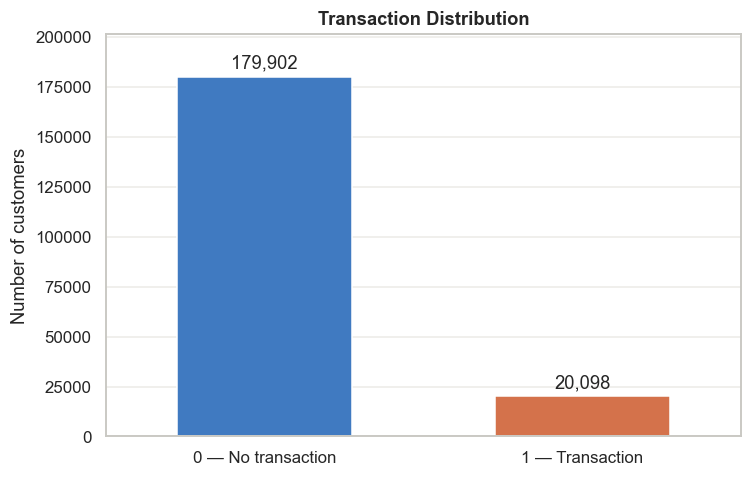

In [11]:
target_counts = df[TARGET_COLUMN].value_counts().sort_index()
target_pct = df[TARGET_COLUMN].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"count": target_counts, "percent": target_pct.round(2)}))

plt.figure(figsize=(7, 4.5))
ax = sns.countplot(data=df, x=TARGET_COLUMN, hue=TARGET_COLUMN, palette=CLASS_COLORS, legend=False, width=0.55)
for container in ax.containers:
    ax.bar_label(container, fmt="{:,.0f}", padding=3)
ax.set_xticks([0, 1], ["0 — No transaction", "1 — Transaction"])
ax.set_xlabel("")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, target_counts.max() * 1.12)
plt.title("Transaction Distribution")
save_fig("target_distribution.png")

**The classes are strongly imbalanced (~90% / ~10%).** A model that always predicts "no transaction" is
already ~90% accurate, so accuracy alone is misleading. We handle this with stratified splits, class
weights, and imbalance-aware metrics (see *Which metric should we choose?* below).

### 7.2 Numerical feature analysis

In [12]:
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

numerical_columns

Index(['target', 'var_0', 'var_1', 'var_2', 'var_3', 'var_4', 'var_5', 'var_6',
       'var_7', 'var_8',
       ...
       'var_190', 'var_191', 'var_192', 'var_193', 'var_194', 'var_195',
       'var_196', 'var_197', 'var_198', 'var_199'],
      dtype='object', length=201)

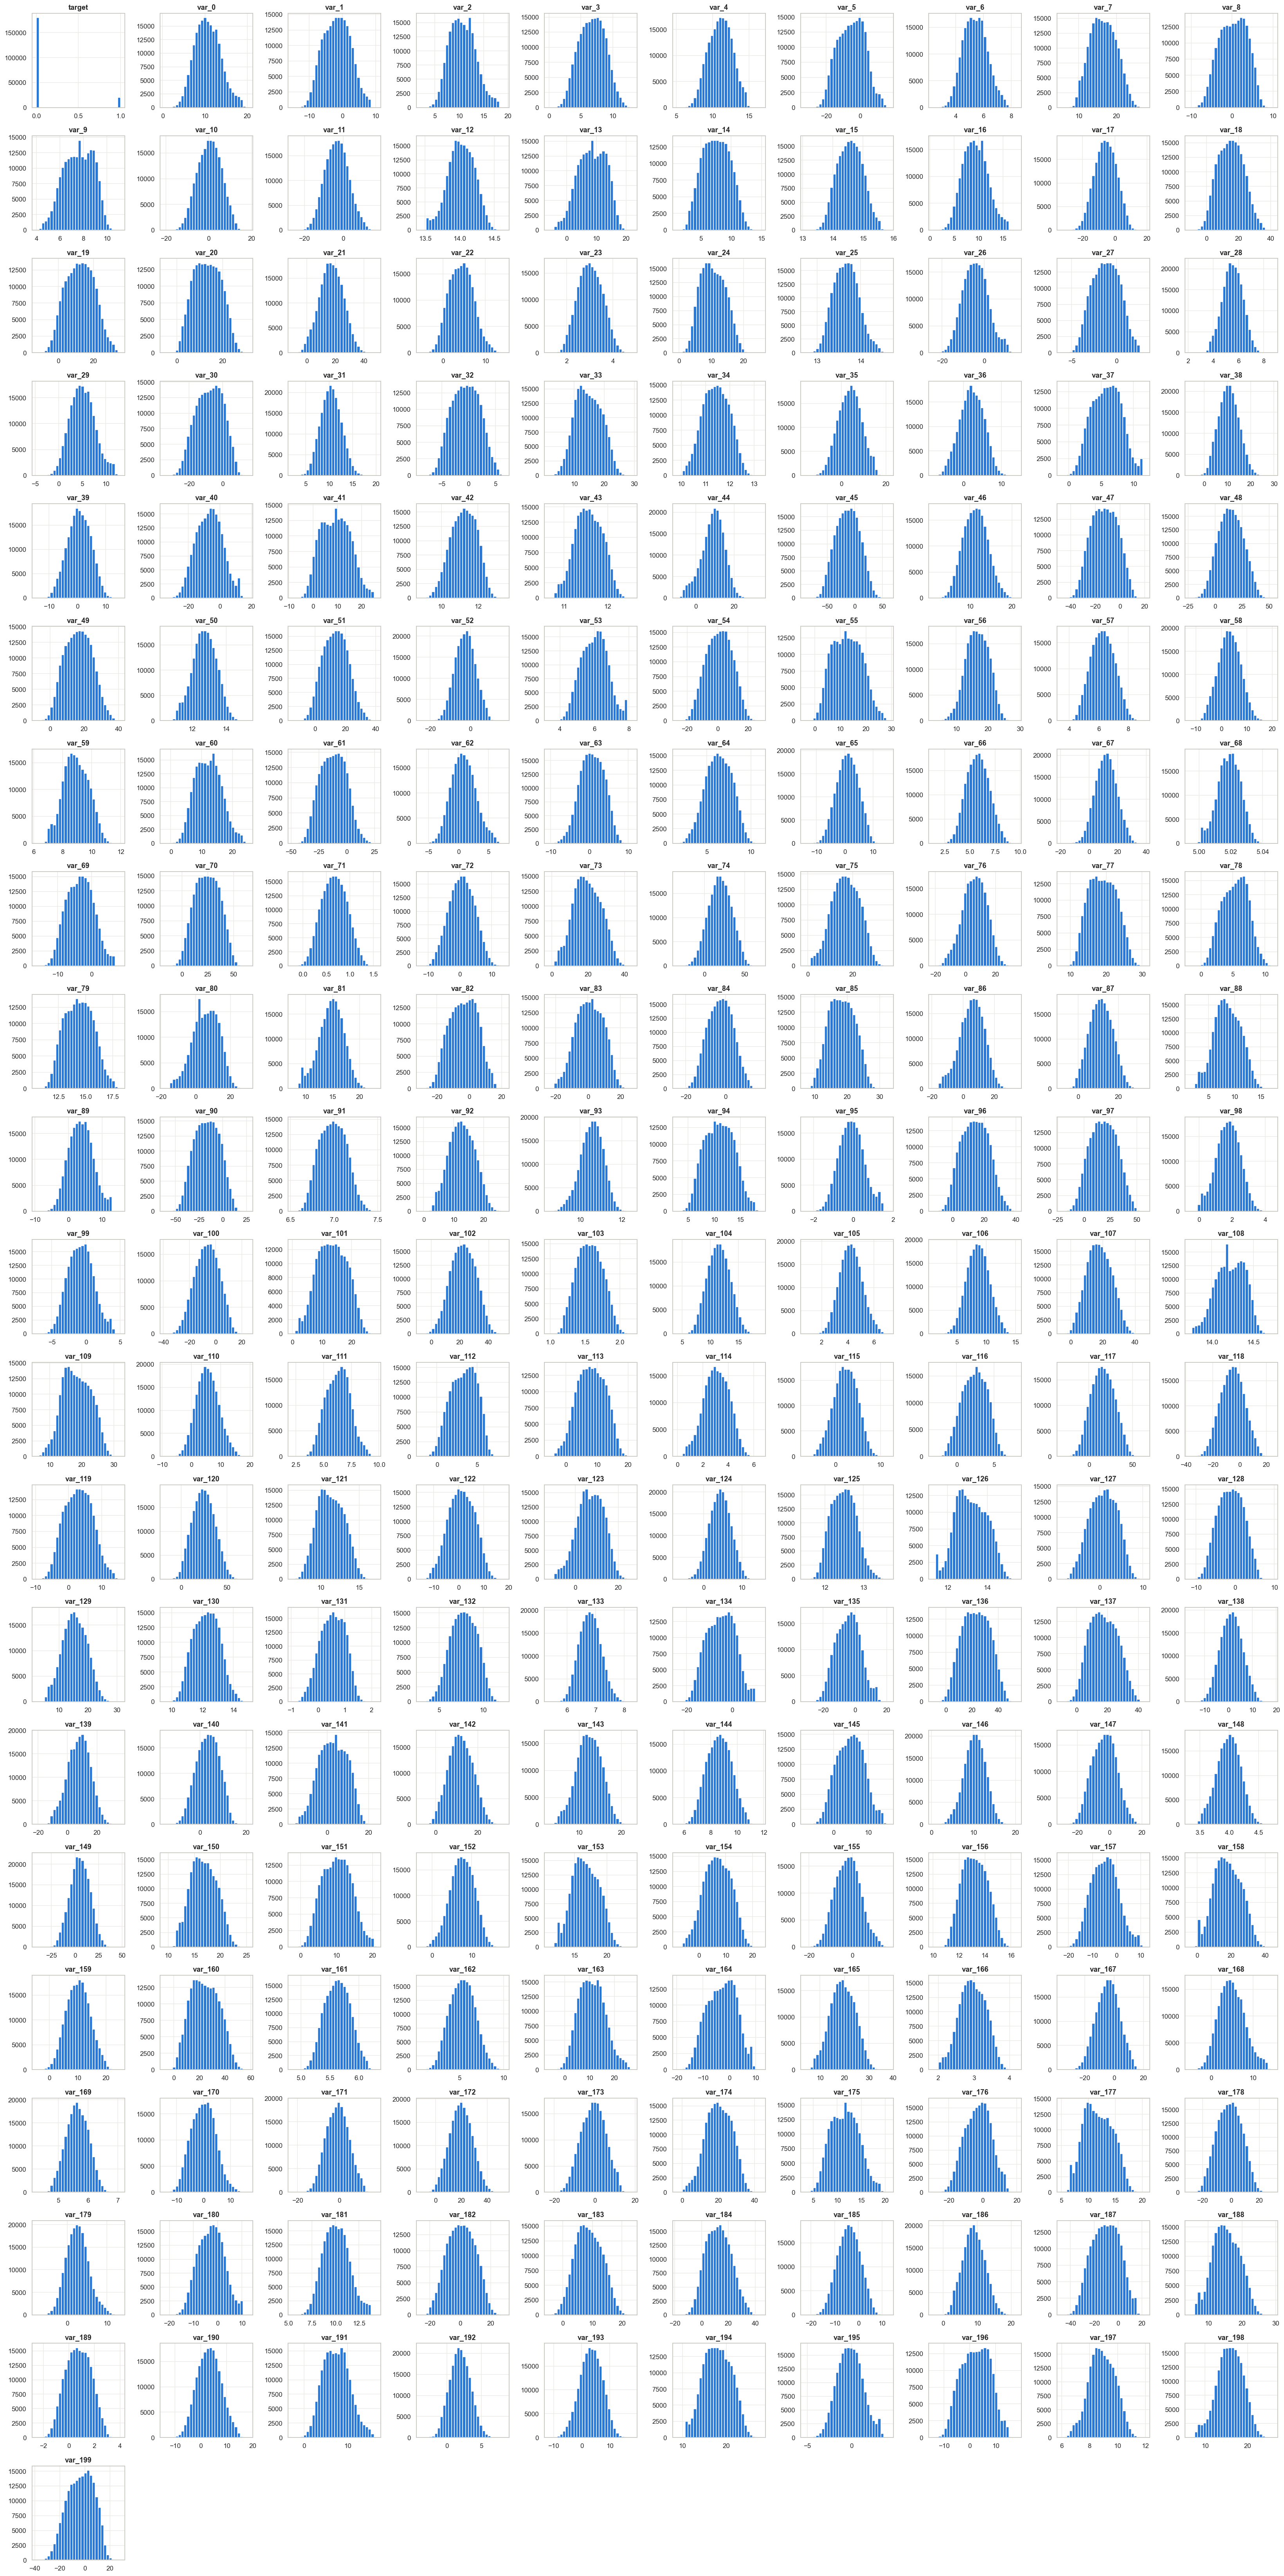

In [13]:
df[numerical_columns].hist(
    figsize=(30, 60),
    bins=30,
    color=BLUE,
    layout=(21, 10),
)

plt.tight_layout()
plt.savefig(FIG_DIR / "numerical_distributions.png", dpi=80)
plt.show()

Almost every feature has a smooth, roughly bell-shaped distribution. A few (for example `var_12`,
`var_108`, `var_68`) are very narrow or show spikes at particular values.

Next we check whether the distributions **differ between the two classes**, using the 12 features most
correlated with the target.

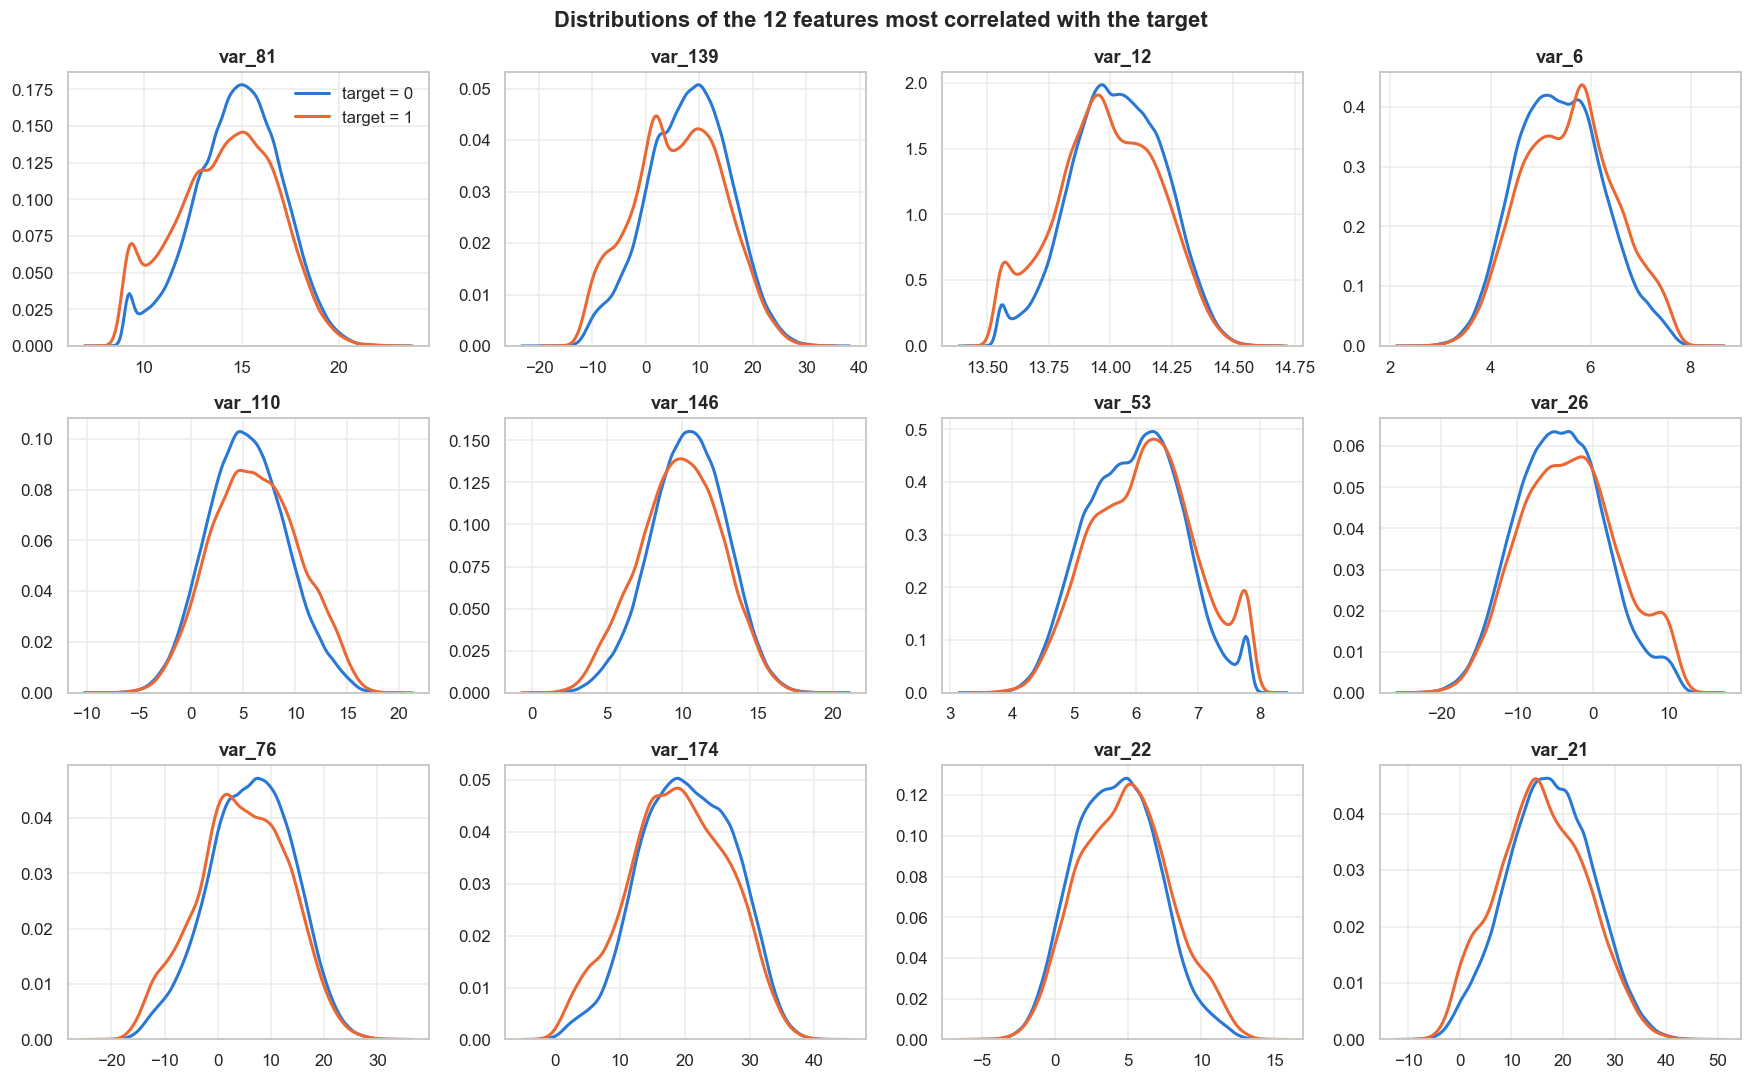

In [14]:
corr_with_target = df[feature_cols].corrwith(df[TARGET_COLUMN]).sort_values()
top_features = list(corr_with_target.abs().sort_values(ascending=False).index[:12])

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), top_features):
    for cls in (0, 1):
        sns.kdeplot(df.loc[df[TARGET_COLUMN] == cls, col], ax=ax, color=CLASS_COLORS[cls],
                    linewidth=2, label=f"target = {cls}")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
axes[0, 0].legend(frameon=False)
fig.suptitle("Distributions of the 12 features most correlated with the target", fontweight="bold")
save_fig("feature_distributions.png")

**Observations**
- The two classes have small but consistent shifts in their distributions.
- No single feature separates the classes on its own; the signal is spread **weakly across many features**.
  That favours models that combine many small effects (boosting, logistic regression).

### 7.3 Categorical feature analysis

In [15]:
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

categorical_columns

Index(['ID_code'], dtype='object')

In [16]:
for column in categorical_columns:
    print(column)
    print(df[column].value_counts())
    print()

ID_code
ID_code
train_0         1
train_133350    1
train_133328    1
train_133329    1
train_133330    1
               ..
train_66668     1
train_66669     1
train_66670     1
train_66671     1
train_199999    1
Name: count, Length: 200000, dtype: int64



In [17]:
for column in categorical_columns:
    print(f"{column}: {df[column].nunique():,} unique values out of {len(df):,} rows")

ID_code: 200,000 unique values out of 200,000 rows


The only categorical column is **`ID_code`**. Every value is unique (one per customer), so it is an
**identifier, not a feature**: it carries no information about behaviour, and one-hot encoding it would
create 200,000 useless columns. It is dropped in preprocessing, which leaves **no categorical features to encode**.

### 7.4 Outlier analysis

In [18]:
q1, q3 = df[feature_cols].quantile(0.25), df[feature_cols].quantile(0.75)
iqr = q3 - q1
outlier_mask = (df[feature_cols] < q1 - 1.5 * iqr) | (df[feature_cols] > q3 + 1.5 * iqr)
outliers_per_feature = outlier_mask.sum().sort_values(ascending=False)
rows_with_any_outlier = outlier_mask.any(axis=1).sum()

print("Total outlier cells (IQR rule)   :", f"{outlier_mask.values.sum():,}")
print("Share of all cells               :", f"{outlier_mask.values.mean() * 100:.2f}%")
print("Rows with at least one outlier   :", f"{rows_with_any_outlier:,} ({rows_with_any_outlier / len(df) * 100:.1f}%)")
print("Target rate in rows w/ outliers  :", f"{df.loc[outlier_mask.any(axis=1), TARGET_COLUMN].mean():.4f}")
print("Target rate in rows w/o outliers :", f"{df.loc[~outlier_mask.any(axis=1), TARGET_COLUMN].mean():.4f}")
outliers_per_feature.head(10).to_frame("outlier_count")

Total outlier cells (IQR rule)   : 26,536
Share of all cells               : 0.07%
Rows with at least one outlier   : 24,896 (12.4%)
Target rate in rows w/ outliers  : 0.1202
Target rate in rows w/o outliers : 0.0977


,outlier_count
var_179,1509
var_44,1208
var_93,889
var_146,804
var_192,733
var_31,637
var_133,589
var_105,572
var_38,502
var_124,498


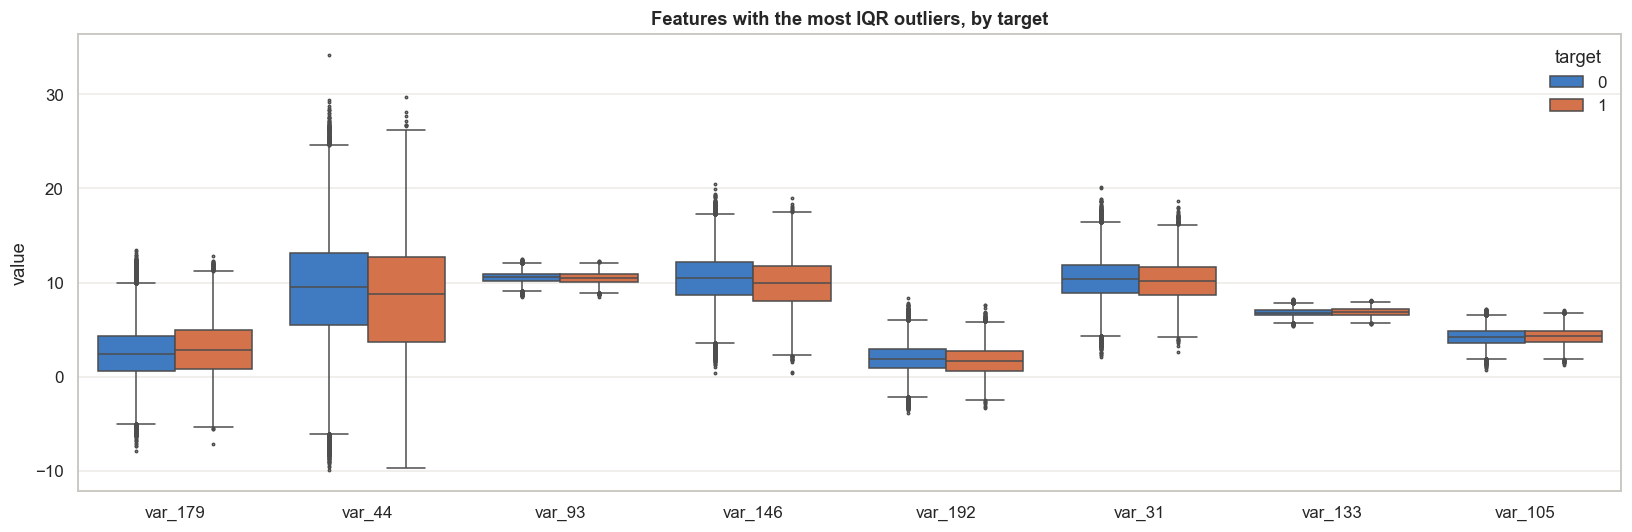

In [19]:
box_cols = list(outliers_per_feature.index[:8])
plot_df = df[box_cols + [TARGET_COLUMN]].melt(id_vars=TARGET_COLUMN, var_name="feature", value_name="value")
fig, ax = plt.subplots(figsize=(15, 5))
sns.boxplot(data=plot_df, x="feature", y="value", hue=TARGET_COLUMN, palette=CLASS_COLORS,
            fliersize=1.5, linewidth=1, ax=ax)
ax.set_title("Features with the most IQR outliers, by target")
ax.set_xlabel("")
ax.legend(title="target", frameon=False)
save_fig("outliers_boxplot.png")

**Decision: keep the outliers.** Only about 0.07% of cells fall outside the IQR fences. That is fewer than a
normal distribution would produce (~0.7%), so these are natural tail values rather than data errors. They are
spread across many columns, though: about 12% of rows contain at least one, and those rows have a *higher*
transaction rate. Removing them would throw away a large share of the data and of the scarce positive class.
Tree models are insensitive to outliers, and standard scaling keeps Logistic Regression stable.

### 7.5 Correlation analysis

Max |correlation| between two features : 0.0098
Mean |correlation| between features    : 0.002


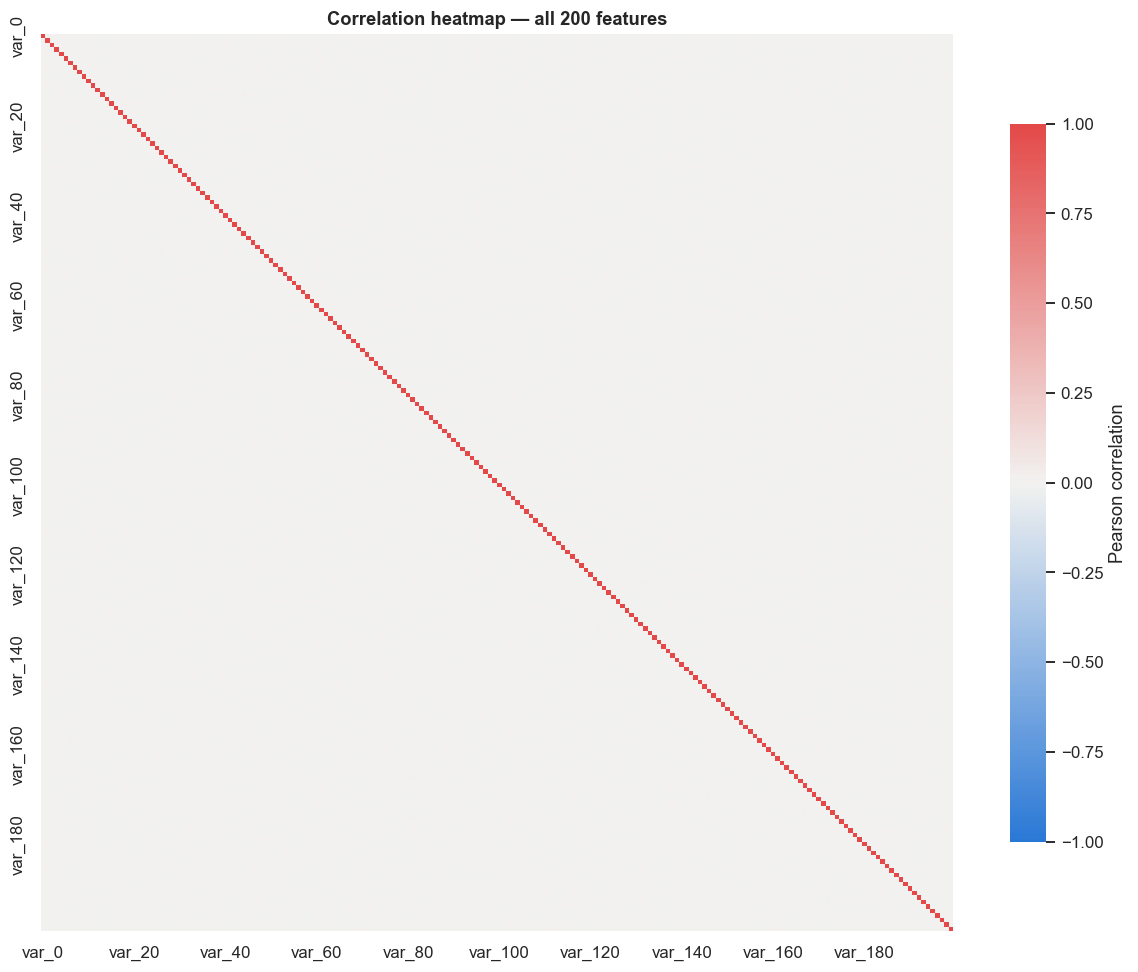

In [20]:
corr = df[feature_cols].corr()
off_diag = corr.where(~np.eye(len(corr), dtype=bool)).abs()
print("Max |correlation| between two features :", round(off_diag.max().max(), 4))
print("Mean |correlation| between features    :", round(off_diag.stack().mean(), 4))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap=DIVERGING, center=0, vmin=-1, vmax=1, xticklabels=20, yticklabels=20,
            cbar_kws={"label": "Pearson correlation", "shrink": 0.8}, ax=ax)
ax.set_title("Correlation heatmap — all 200 features")
save_fig("correlation_heatmap.png")

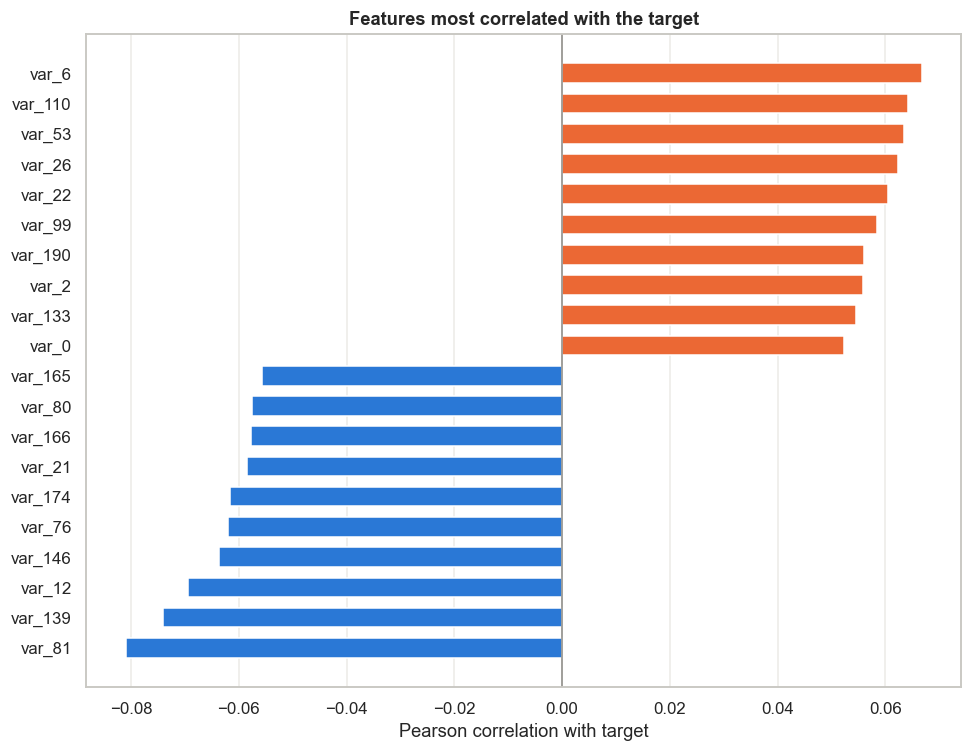

Strongest single-feature correlation with target: 0.0809


In [21]:
top_corr = pd.concat([corr_with_target.head(10), corr_with_target.tail(10)])

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_corr.index, top_corr.values, color=[BLUE if v < 0 else ORANGE for v in top_corr.values], height=0.65)
ax.axvline(0, color=GRAY, linewidth=1)
ax.set_title("Features most correlated with the target")
ax.set_xlabel("Pearson correlation with target")
ax.grid(axis="y", visible=False)
save_fig("target_correlation.png")
print("Strongest single-feature correlation with target:", round(corr_with_target.abs().max(), 4))

**Observations**
- Features are almost **completely uncorrelated with each other** (max |r| ≈ 0.01): there is no multicollinearity, so no PCA or feature dropping is needed.
- Each feature is only **weakly correlated with the target** (|r| ≤ ~0.08). The predictive power comes from combining many features.

## Step 8 — Data preprocessing

```
Raw dataset
   ↓  Remove duplicates
   ↓  Handle missing values
   ↓  Separate X and y
   ↓  Train/test split
   ↓  Identify numerical columns
   ↓  Identify categorical columns
   ↓  Encode categorical variables   (OneHotEncoder)
   ↓  Scale numerical variables      (StandardScaler)
   ↓  Preprocessing pipeline         (ColumnTransformer)
```

The train/test split happens **before** fitting the encoder and scaler. They learn only from the training
data, so no information from the test set leaks into training.

### 8.1 Remove duplicates

In [22]:
rows_before = len(df)
df = df.drop_duplicates()
print(f"Removed {rows_before - len(df)} duplicate rows → {len(df):,} rows remain")

Removed 0 duplicate rows → 200,000 rows remain


### 8.2 Handle missing values

In [23]:
print("Missing values in the dataset:", df.isnull().sum().sum())

Missing values in the dataset: 0


There are no missing values, so no rows need to be dropped or filled now. The preprocessing pipeline still
includes a `SimpleImputer` (median for numbers, most frequent for categories). It does nothing on this
dataset but protects the deployed model if a future record arrives with a missing value.

### 8.3 Separate features and target

In [24]:
X = df.drop(columns=[TARGET_COLUMN, "ID_code"])
y = df[TARGET_COLUMN]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (200000, 200)
y shape: (200000,)


### 8.4 Train-test split

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("X_train:", X_train.shape, "| transaction rate:", round(y_train.mean(), 4))
print("X_test :", X_test.shape,  "| transaction rate:", round(y_test.mean(), 4))

X_train: (160000, 200) | transaction rate: 0.1005
X_test : (40000, 200) | transaction rate: 0.1005


### 8.5 Identify numerical and categorical columns

In [26]:
numerical_features = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

print("Numerical features  :", len(numerical_features))
print("Categorical features:", len(categorical_features), categorical_features)

Numerical features  : 200
Categorical features: 0 []


### 8.6 Numerical preprocessing

In [27]:
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
numerical_transformer

,steps,"[('imputer', ...), ('scaler', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


### 8.7 Categorical preprocessing

In [28]:
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
categorical_transformer

,steps,"[('imputer', ...), ('encoder', ...)]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,categories,'auto'


This dataset has **no categorical features** after removing `ID_code`, so the categorical branch receives an
empty column list and is skipped. It stays in the pipeline so that the same code works if categorical columns
are added later.

### 8.8 Create preprocessing pipeline

In [29]:
preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features),
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed X_train:", X_train_processed.shape)
print("Processed X_test :", X_test_processed.shape)
pd.DataFrame(X_train_processed[:, :8], columns=numerical_features[:8]).describe().loc[["mean", "std"]].round(3)

Processed X_train: (160000, 200)
Processed X_test : (40000, 200)


,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7
mean,0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [30]:
processed_feature_names = [n.split("__", 1)[1] for n in preprocessor.get_feature_names_out()]
processed = pd.concat([
    pd.DataFrame(X_train_processed, columns=processed_feature_names, index=X_train.index).assign(target=y_train, split="train"),
    pd.DataFrame(X_test_processed, columns=processed_feature_names, index=X_test.index).assign(target=y_test, split="test"),
]).sort_index()
processed.to_csv(PROCESSED_PATH, index=False, float_format="%.6f")
print("Saved:", PROCESSED_PATH, processed.shape)

Saved: data/processed/processed_data.csv (200000, 202)


Each model below is a **`Pipeline(preprocessor → model)`**. This keeps preprocessing and model together:
- during cross-validation the scaler is refit inside every fold (no leakage), and
- the saved model accepts raw customer data and preprocesses it automatically.

**Algorithm selection**

| Model | Role | Why it fits this data |
|-------|------|-----------------------|
| **Logistic Regression** | Baseline | Fast and interpretable. Outputs a probability. Works well when the signal is a sum of many small, independent effects |
| **Random Forest** | Bagging ensemble | Many decision trees on bootstrap samples, averaged. Captures non-linear patterns and is robust to outliers |
| **XGBoost** | Boosting ensemble | Trees built one after another, each correcting the previous errors. Usually the strongest on tabular data, with built-in regularisation and `scale_pos_weight` for imbalance |

**Imbalance handling:** `class_weight="balanced"` for LR and RF, and `scale_pos_weight = negatives / positives` for XGBoost.

In [31]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight for XGBoost:", round(scale_pos_weight, 3))

models, train_times = {}, {}

def train(name, estimator):
    pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    start = time.time()
    pipeline.fit(X_train, y_train)
    train_times[name] = time.time() - start
    models[name] = pipeline
    test_auc = roc_auc_score(y_test, pipeline.predict_proba(X_test)[:, 1])
    print(f"{name} trained in {train_times[name]:.1f} s — test ROC-AUC {test_auc:.4f}")
    return pipeline

scale_pos_weight for XGBoost: 8.951


## Step 9 — Train Logistic Regression

In [32]:
log_reg_model = train("Logistic Regression", LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE,
))
log_reg_model

Logistic Regression trained in 3.5 s — test ROC-AUC 0.8599


,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Step 10 — Train Random Forest

In [33]:
rf_model = train("Random Forest", RandomForestClassifier(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=20,
    max_features="sqrt",
    class_weight="balanced_subsample",
    n_jobs=-1,
    random_state=RANDOM_STATE,
))

Random Forest trained in 61.1 s — test ROC-AUC 0.8279


## Step 11 — Train XGBoost

In [34]:
xgb_model = train("XGBoost", XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.5,
    scale_pos_weight=scale_pos_weight,
    tree_method="hist",
    eval_metric="auc",
    n_jobs=-1,
    random_state=RANDOM_STATE,
))

XGBoost trained in 14.8 s — test ROC-AUC 0.8871


## Step 12 — Evaluate the models
For each model we calculate **Accuracy, Precision, Recall, F1 score and ROC-AUC** on the test set
(threshold 0.5).

In [35]:
def evaluate(model, X_eval, y_eval, threshold=0.5):
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall": recall_score(y_eval, pred),
        "F1": f1_score(y_eval, pred),
        "ROC-AUC": roc_auc_score(y_eval, proba),
    }, proba

results, probas = {}, {}
for name, model in models.items():
    results[name], probas[name] = evaluate(model, X_test, y_test)
    results[name]["Train ROC-AUC"] = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
    results[name]["Train time (s)"] = train_times[name]

results_df = pd.DataFrame(results).T
results_df.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC,Train ROC-AUC,Train time (s)
Logistic Regression,0.7834,0.2865,0.7754,0.4184,0.8599,0.8615,3.5353
Random Forest,0.9071,0.6289,0.1851,0.2860,0.8279,0.9856,61.1208
XGBoost,0.8425,0.3637,0.7565,0.4912,0.8871,0.9288,14.8027


In [36]:
for name in models:
    print(f"===== {name} =====")
    print(classification_report(y_test, (probas[name] >= 0.5).astype(int),
                                target_names=["No transaction", "Transaction"], digits=4))

===== Logistic Regression =====
                precision    recall  f1-score   support

No transaction     0.9690    0.7843    0.8669     35980
   Transaction     0.2865    0.7754    0.4184      4020

      accuracy                         0.7834     40000
     macro avg     0.6278    0.7798    0.6427     40000
  weighted avg     0.9004    0.7834    0.8218     40000

===== Random Forest =====
                precision    recall  f1-score   support

No transaction     0.9156    0.9878    0.9503     35980
   Transaction     0.6289    0.1851    0.2860      4020

      accuracy                         0.9071     40000
     macro avg     0.7723    0.5864    0.6182     40000
  weighted avg     0.8868    0.9071    0.8836     40000

===== XGBoost =====
                precision    recall  f1-score   support

No transaction     0.9691    0.8521    0.9068     35980
   Transaction     0.3637    0.7565    0.4912      4020

      accuracy                         0.8425     40000
     macro avg    

### Compare the algorithms

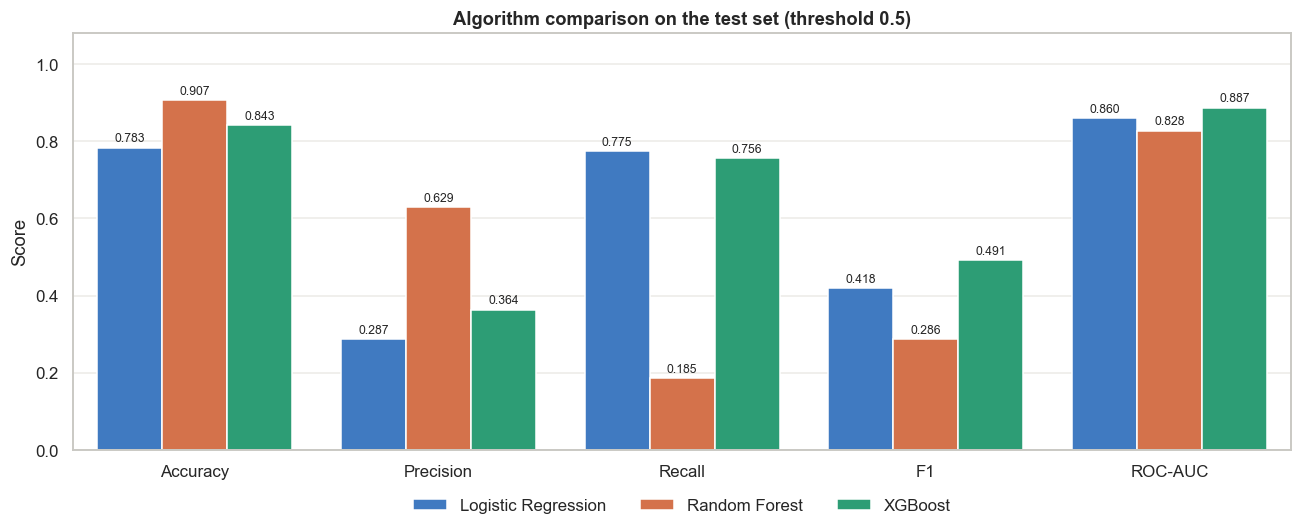

In [37]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
plot_df = results_df[metrics_to_plot].reset_index(names="Model").melt(id_vars="Model", var_name="Metric", value_name="Score")

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette=MODEL_COLORS, ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8, padding=2)
ax.set_ylim(0, 1.08)
ax.set_xlabel("")
ax.set_title("Algorithm comparison on the test set (threshold 0.5)")
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.08))
save_fig("algorithm_comparison.png")

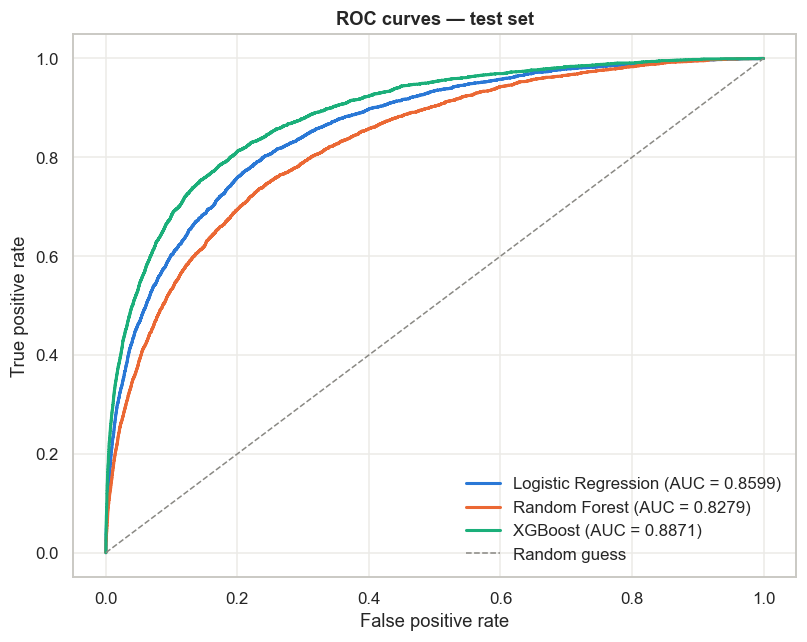

In [38]:
fig, ax = plt.subplots(figsize=(7.5, 6))
for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    ax.plot(fpr, tpr, color=MODEL_COLORS[name], linewidth=2,
            label=f"{name} (AUC = {roc_auc_score(y_test, proba):.4f})")
ax.plot([0, 1], [0, 1], color=GRAY, linestyle="--", linewidth=1, label="Random guess")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves — test set")
ax.legend(frameon=False, loc="lower right")
save_fig("roc_curves.png")

**Observations**
- **Random Forest** has the highest *accuracy* but by far the lowest *recall*: it finds very few of the
  actual transactions, and its accuracy mostly comes from predicting the majority class. It also has the
  largest gap between train and test ROC-AUC (overfitting).
- **Logistic Regression** is a strong baseline because the signal is close to additive across independent features.
- **XGBoost** has the best ROC-AUC and F1. Boosting stacks up many small per-feature effects.

### Which metric should we choose?

| Metric | Question it answers |
|--------|---------------------|
| **Accuracy** | How many predictions were correct overall? |
| **Precision** | When the model says *Transaction*, how often is it actually a transaction? |
| **Recall** | Of all actual transactions, how many did the model find? |
| **F1** | The balance between precision and recall (their harmonic mean) |
| **ROC-AUC** | How well does the model separate the two classes, across *all* thresholds? |

Accuracy is a trap on imbalanced data. A "model" that always predicts *No transaction* scores:

In [39]:
always_no = np.zeros_like(y_test)
print(f"Accuracy of always predicting 'No transaction': {accuracy_score(y_test, always_no):.4f}")
print(f"Recall of always predicting 'No transaction'  : {recall_score(y_test, always_no):.4f}")

Accuracy of always predicting 'No transaction': 0.8995
Recall of always predicting 'No transaction'  : 0.0000


That is ~90% accuracy while finding **zero** transactions. For this imbalanced dataset we therefore focus on
**F1, Recall, Precision and ROC-AUC** rather than accuracy:

- **ROC-AUC** is used to **choose the algorithm** and to **tune hyperparameters**. It does not depend on a threshold or on the class balance.
- **F1** (precision and recall together) is used to **choose the decision threshold** of the final model.
  The bank can move this threshold: a lower threshold catches more future transactions (higher recall),
  a higher threshold gives a smaller, more certain target list (higher precision).

## Step 13 — Confusion Matrix

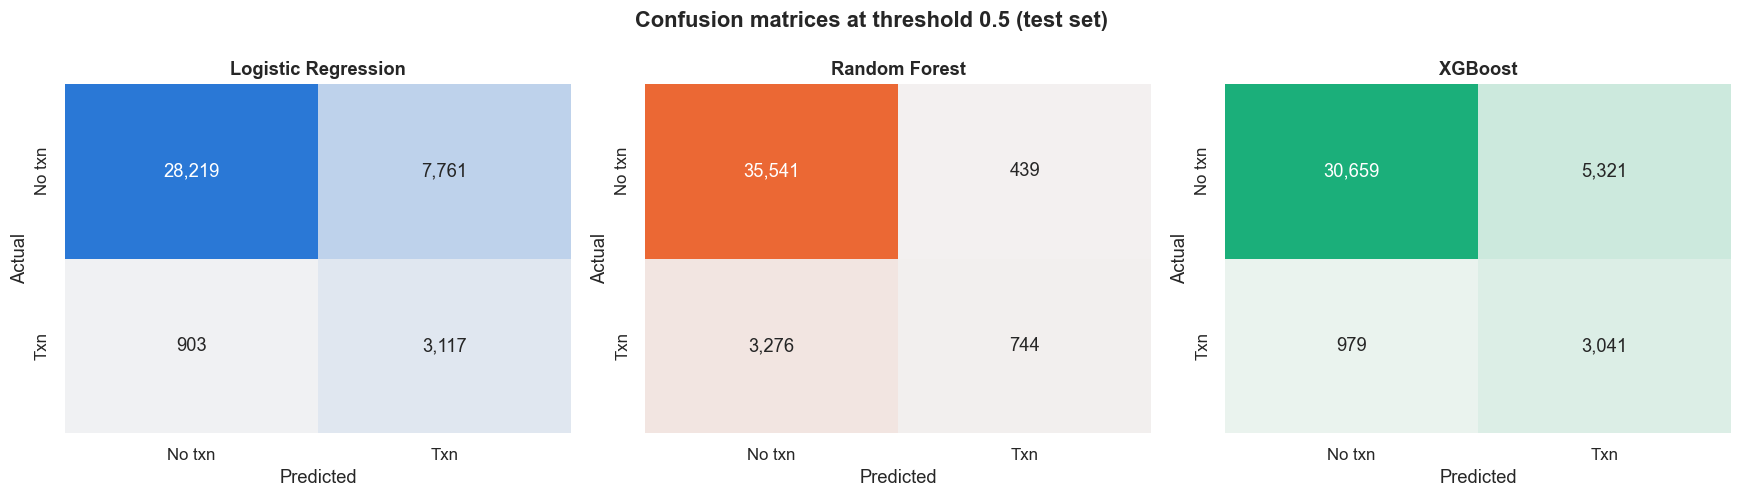

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (name, proba) in zip(axes, probas.items()):
    cm = confusion_matrix(y_test, (proba >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt=",d", cmap=sns.light_palette(MODEL_COLORS[name], as_cmap=True),
                cbar=False, ax=ax, xticklabels=["No txn", "Txn"], yticklabels=["No txn", "Txn"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
fig.suptitle("Confusion matrices at threshold 0.5 (test set)", fontweight="bold")
save_fig("confusion_matrices_baseline.png")

How to read it: **top-left** = correctly predicted no-transaction customers, **bottom-right** = correctly found
transactions, **bottom-left** = transactions the model missed (false negatives), **top-right** = customers wrongly
flagged (false positives). Random Forest misses most actual transactions (large bottom-left cell).

## Step 14 — Cross-validation
5-fold stratified cross-validation on the training set checks that the ranking is stable and not the result
of one lucky train/test split.

In [41]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = {}
for name, model in models.items():
    start = time.time()
    cv_scores[name] = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    print(f"{name:20s} CV ROC-AUC = {cv_scores[name].mean():.4f} ± {cv_scores[name].std():.4f}"
          f"   ({time.time() - start:.0f} s)")

cv_df = pd.DataFrame(cv_scores, index=[f"Fold {i}" for i in range(1, 6)]).T
cv_df["Mean"] = cv_df.mean(axis=1)
cv_df["Std"] = cv_df.iloc[:, :5].std(axis=1)
cv_df = cv_df.sort_values("Mean", ascending=False)
cv_df.round(4)

Logistic Regression  CV ROC-AUC = 0.8590 ± 0.0031   (14 s)
Random Forest        CV ROC-AUC = 0.8324 ± 0.0045   (325 s)
XGBoost              CV ROC-AUC = 0.8877 ± 0.0023   (98 s)


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean,Std
XGBoost,0.8856,0.8887,0.8918,0.8859,0.8867,0.8877,0.0026
Logistic Regression,0.8587,0.8573,0.8650,0.8579,0.8561,0.8590,0.0035
Random Forest,0.8298,0.8316,0.8413,0.8301,0.8291,0.8324,0.0051


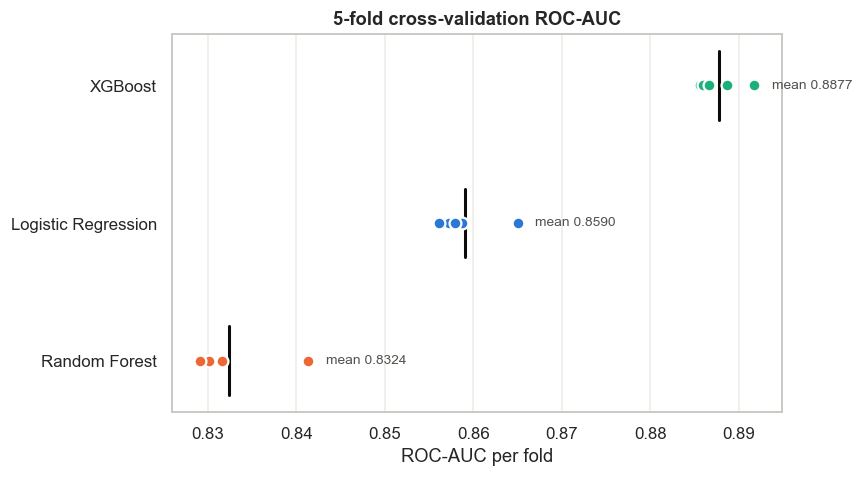

In [42]:
fig, ax = plt.subplots(figsize=(8, 4.5))
order = list(cv_df.index)
for i, name in enumerate(order):
    scores = cv_scores[name]
    ax.scatter(scores, [i] * len(scores), color=MODEL_COLORS[name], s=60, zorder=3, edgecolor="white", linewidth=1.5)
    ax.plot([scores.mean()] * 2, [i - 0.25, i + 0.25], color="#0b0b0b", linewidth=2)
    ax.text(scores.max() + 0.002, i, f"mean {scores.mean():.4f}", va="center", fontsize=9, color="#52514e")
ax.set_yticks(range(len(order)), order)
ax.invert_yaxis()
ax.set_xlabel("ROC-AUC per fold")
ax.set_title("5-fold cross-validation ROC-AUC")
ax.grid(axis="y", visible=False)
save_fig("cross_validation.png")

In [43]:
best_algorithm = cv_df["Mean"].idxmax()
print("Best algorithm by cross-validated ROC-AUC:", best_algorithm)

Best algorithm by cross-validated ROC-AUC: XGBoost


## Step 15 — Hyperparameter tuning
We tune the best algorithm from cross-validation with `RandomizedSearchCV`: 15 random parameter combinations
× 3-fold stratified CV, optimising ROC-AUC. Randomized search covers a large space far more cheaply than an
exhaustive grid search. Parameters are prefixed with `model__` because the model sits inside the pipeline.

In [ ]:
search_spaces = {
    "XGBoost": {
        "model__n_estimators": [1000, 1500, 2000, 3000],
        "model__learning_rate": [0.02, 0.03, 0.05, 0.08],
        "model__max_depth": [1, 2, 3],
        "model__subsample": [0.6, 0.7, 0.8, 1.0],
        "model__colsample_bytree": [0.1, 0.2, 0.3, 0.5],
        "model__min_child_weight": [1, 5, 10, 20],
        "model__reg_lambda": [1, 5, 10],
    },
    "Logistic Regression": {
        "model__C": np.logspace(-4, 2, 20),
        "model__solver": ["lbfgs", "liblinear"],
    },
    "Random Forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [10, 15, 20, None],
        "model__min_samples_leaf": [5, 10, 20, 50],
        "model__max_features": ["sqrt", 0.1, 0.2],
    },
}

search = RandomizedSearchCV(
    models[best_algorithm],
    param_distributions=search_spaces[best_algorithm],
    n_iter=15,
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1,
    refit=True,
)

start = time.time()
search.fit(X_train, y_train)
print(f"Search finished in {(time.time() - start) / 60:.1f} min")
print("Best CV ROC-AUC :", round(search.best_score_, 4))
print("Best parameters :", search.best_params_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits


Search finished in 12.8 min
Best CV ROC-AUC : 0.8941
Best parameters : {'model__subsample': 0.7, 'model__reg_lambda': 1, 'model__n_estimators': 2000, 'model__min_child_weight': 10, 'model__max_depth': 3, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.3}


In [ ]:
(pd.DataFrame(search.cv_results_)
   .sort_values("rank_test_score")
   [["rank_test_score", "mean_test_score", "std_test_score", "mean_fit_time", "params"]]
   .head(10).round(4))

## Step 16 — Evaluate the final model

In [ ]:
final_model = search.best_estimator_
tuned_metrics, tuned_proba = evaluate(final_model, X_test, y_test)

comparison = results_df[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].copy()
comparison.loc[f"{best_algorithm} (tuned)"] = tuned_metrics
comparison["CV ROC-AUC"] = [cv_df.loc[n, "Mean"] if n in cv_df.index else search.best_score_
                            for n in comparison.index]
comparison = comparison.sort_values("ROC-AUC", ascending=False)
comparison.round(4)

### Choosing the decision threshold
The default threshold of 0.5 is arbitrary for an imbalanced, class-weighted model. We choose the threshold
that **maximises F1 for the transaction class**. To keep the test set untouched, the threshold comes from
**out-of-fold predictions on the training set**, not from the test set.

In [ ]:
oof_proba = cross_val_predict(final_model, X_train, y_train,
                              cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
                              method="predict_proba", n_jobs=1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1_curve = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
best_threshold = float(thr[np.argmax(f1_curve)])
print("Out-of-fold ROC-AUC :", round(roc_auc_score(y_train, oof_proba), 4))
print("Best threshold (F1) :", round(best_threshold, 4))

final_metrics, final_proba = evaluate(final_model, X_test, y_test, threshold=best_threshold)
final_pred = (final_proba >= best_threshold).astype(int)
pd.DataFrame({"threshold 0.5": tuned_metrics, f"threshold {best_threshold:.3f}": final_metrics}).round(4)

In [ ]:
print(classification_report(y_test, final_pred, target_names=["No transaction", "Transaction"], digits=4))

cm = confusion_matrix(y_test, final_pred)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100
labels = np.array([[f"{cm[i, j]:,}\n({cm_pct[i, j]:.1f}% of row)" for j in range(2)] for i in range(2)])
fig, ax = plt.subplots(figsize=(6.5, 5.2))
sns.heatmap(cm, annot=labels, fmt="", cmap=sns.light_palette(BLUE, as_cmap=True), cbar=False, ax=ax,
            xticklabels=["No transaction", "Transaction"], yticklabels=["No transaction", "Transaction"],
            annot_kws={"fontsize": 11})
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Final model — confusion matrix (threshold {best_threshold:.3f})")
save_fig("confusion_matrix.png")

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_comp = comparison["ROC-AUC"].sort_values()
colors = [MODEL_COLORS.get(n.replace(" (tuned)", ""), GRAY) for n in plot_comp.index]
ax.barh(plot_comp.index, plot_comp.values, color=colors, height=0.6)
for i, v in enumerate(plot_comp.values):
    ax.text(v + 0.002, i, f"{v:.4f}", va="center", fontsize=10, color="#0b0b0b")
ax.set_xlim(0.5, 1.0)
ax.set_xlabel("Test ROC-AUC")
ax.set_title("Model comparison — test ROC-AUC")
ax.grid(axis="y", visible=False)
save_fig("model_comparison.png")

## Step 17 — Feature importance

In [ ]:
final_estimator = final_model.named_steps["model"]
feature_names = [n.split("__", 1)[1] for n in final_model.named_steps["preprocessor"].get_feature_names_out()]
if hasattr(final_estimator, "feature_importances_"):
    importance = pd.Series(final_estimator.feature_importances_, index=feature_names)
    importance_label = "Feature importance (gain share)"
else:
    importance = pd.Series(np.abs(final_estimator.coef_[0]), index=feature_names)
    importance_label = "|coefficient| (standardised features)"
top_importance = importance.sort_values(ascending=False).head(20).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_importance.index, top_importance.values, color=BLUE, height=0.65)
ax.set_title(f"Top 20 features — {best_algorithm} (tuned)")
ax.set_xlabel(importance_label)
ax.grid(axis="y", visible=False)
save_fig("feature_importance.png")

print("Top 5 features:", list(top_importance.sort_values(ascending=False).index[:5]))
print(f"Top 20 features together account for {top_importance.sum() / importance.sum() * 100:.1f}% of total importance")

The importance is spread thinly across many features. Even the top 20 features account for only a small share
of the total, which confirms the EDA finding: there is no dominant feature, and the model relies on the combined
weak signal of all 200.

## Step 18 — Save the model

In [ ]:
model_bundle = {
    "model": final_model,
    "model_name": f"{best_algorithm} (tuned)",
    "features": numerical_features + categorical_features,
    "threshold": best_threshold,
    "best_params": search.best_params_,
    "metrics": {k: round(float(v), 4) for k, v in final_metrics.items()},
    "top_features": list(importance.sort_values(ascending=False).index[:20]),
}
joblib.dump(model_bundle, MODEL_PATH)
print("Saved:", MODEL_PATH, f"({MODEL_PATH.stat().st_size / 1024**2:.2f} MB)")

## Step 19 — Load the saved model

A production system never retrains to predict. It loads the saved pipeline from disk, as we do here.

In [ ]:
bundle = joblib.load(MODEL_PATH)

print("Model           :", bundle["model_name"])
print("Pipeline steps  :", list(bundle["model"].named_steps))
print("Input features  :", len(bundle["features"]))
print("Threshold       :", round(bundle["threshold"], 4))
print("Test metrics    :", bundle["metrics"])
bundle["model"]

In [ ]:
reloaded_auc = roc_auc_score(y_test, bundle["model"].predict_proba(X_test)[:, 1])
print("Reloaded model test ROC-AUC:", round(reloaded_auc, 4))

## Step 20 — Make a new prediction

A typical customer form would ask for **Age, Income, Gender, Occupation**. This dataset has none of those
fields: the bank anonymized every attribute as `var_0` … `var_199` (all numeric). A new customer is therefore a
record with values for those 200 attributes, which is exactly what the saved pipeline expects.

In [ ]:
def predict_customers(records: pd.DataFrame, bundle=bundle) -> pd.DataFrame:
    proba = bundle["model"].predict_proba(records[bundle["features"]])[:, 1]
    return pd.DataFrame({
        "transaction_probability": proba.round(4),
        "prediction": (proba >= bundle["threshold"]).astype(int),
    }, index=records.index).assign(
        prediction_label=lambda d: d["prediction"].map({0: "No transaction", 1: "Transaction"}))

In [ ]:
new_customer = X_test.iloc[0].round(4).to_dict()
print("New customer (first 8 of 200 attributes):")
print({k: new_customer[k] for k in list(new_customer)[:8]})

new_customer_df = pd.DataFrame([new_customer])
predict_customers(new_customer_df)

In [ ]:
sample = X_test.sample(10, random_state=RANDOM_STATE)
example_predictions = predict_customers(sample).assign(
    actual=y_test.loc[sample.index], ID_code=df.loc[sample.index, "ID_code"])
example_predictions

## Step 21 — Deployment

```
Client (another system, script or curl)
  │  HTTP POST /predict
  ▼
FastAPI  (deployment/app.py)
  │
  ▼
Saved ML pipeline (.pkl)  — preprocessing + tuned XGBoost
  │
  ▼
Customer transaction prediction
  │
  ▼
Response  — probability + Transaction / No transaction
```

### FastAPI — `deployment/app.py`
Loads `models/customer_transaction_model.pkl` once at startup. The saved pipeline does all preprocessing itself.

| Endpoint | Method | Purpose |
|----------|--------|---------|
| `/health` | GET | Liveness check and model info |
| `/predict` | POST | Score one customer: `{"features": {"var_0": 11.2, ..., "var_199": -3.1}}` |
| `/predict/batch` | POST | Score many customers: `{"customers": [{"features": {...}}, ...]}` |

### Run it (from the project folder)
```bash
uvicorn deployment.app:app --reload
```
The API then runs on http://127.0.0.1:8000, with interactive docs at http://127.0.0.1:8000/docs.

The cell below writes an example request body (used by the tests) and picks six sample customers for the report.

In [ ]:
example = {"features": {k: round(float(v), 4) for k, v in X_test.iloc[0].items()}}
(ROOT / "deployment" / "example_request.json").write_text(json.dumps(example, indent=2))

samples = pd.concat([y_test[y_test == 1].sample(3, random_state=RANDOM_STATE),
                     y_test[y_test == 0].sample(3, random_state=RANDOM_STATE)])
print("Wrote deployment/example_request.json")
print("Sample customers for the report:", list(df.loc[samples.index, "ID_code"]))

## Step 22 — Testing
`tests/test_prediction.py` checks the deployed path end to end with `pytest`:

```
Model loads → Input accepted → Prediction generated → Probability returned
```

It also checks that the API probability matches the model's own probability, that batch prediction works, and
that incomplete input is rejected with a clear error.

In [ ]:
import subprocess
import sys

result = subprocess.run([sys.executable, "-m", "pytest", "tests", "-v", "--no-header", "--color=no", "-p", "no:cacheprovider",
                         "-p", "no:warnings"],
                        capture_output=True, text=True, cwd=ROOT)
print(result.stdout[-3000:])
print("All tests passed" if result.returncode == 0 else f"TESTS FAILED (exit code {result.returncode})")

## Step 23 — Final report
The report is built once from the results computed above. It is shown below in the notebook and exported as
`reports/Customer_Transaction_Report.pdf`, so the two always contain the same numbers.

### Model Comparison Report
Performance of every model on the same 40,000-customer test set, with 5-fold cross-validated ROC-AUC (precision, recall and F1 at threshold 0.5).

In [ ]:
comparison.round(4)

In [ ]:
best_row = comparison.iloc[0]
runner_up = comparison.iloc[1]
print(f"Recommended production model : {comparison.index[0]}")
print(f"Test ROC-AUC                 : {best_row['ROC-AUC']:.4f} (runner-up {comparison.index[1]}: {runner_up['ROC-AUC']:.4f})")
print(f"Decision threshold           : {best_threshold:.3f}")
print(f"At that threshold: precision {final_metrics['Precision']:.3f}, recall {final_metrics['Recall']:.3f}, F1 {final_metrics['F1']:.3f}")

**Recommended model for production: tuned XGBoost.**

1. **Highest discrimination:** best ROC-AUC on the held-out test set and in cross-validation.
2. **Stable:** fold-to-fold variation in cross-validation is small, so the result does not depend on a lucky split.
3. **Handles the imbalance natively** through `scale_pos_weight`.
4. **Production-friendly:** the saved pipeline is small, predicts in milliseconds, and its probability output lets the bank move the threshold to match its campaign budget.

Logistic Regression is a close, fully interpretable fallback. Random Forest is not recommended: it has the lowest ROC-AUC, misses most actual transactions, and overfits the most.

### Report on Challenges Faced

| # | Challenge | Technique used | Reason |
|---|-----------|----------------|--------|
| 1 | **Class imbalance** (~10% positives) | Stratified split and CV; `class_weight="balanced"` / `scale_pos_weight`; ROC-AUC and F1 instead of accuracy; F1-optimal threshold | Accuracy rewards always predicting "no transaction" (~90% accuracy, 0 transactions found). Class weights fix the bias without inventing synthetic rows |
| 2 | **Anonymized features** (no names or meaning) | Purely statistical EDA; model-based feature importance | Domain-based feature engineering was impossible, so the analysis relied on data behaviour |
| 3 | **Weak signal per feature** (max \|r\| with target ≈ 0.08) | Kept all 200 features; models that add up many small effects (boosting, LR) | Dropping "weak" features would remove real signal, because the prediction comes from their combination |
| 4 | **Identifier column** (`ID_code`) | Excluded from the features | It is unique per customer; encoding it would create 200,000 meaningless columns |
| 5 | **Different feature scales** | `StandardScaler` inside a `ColumnTransformer` + `Pipeline` | Needed for Logistic Regression; inside the pipeline it is refitted per CV fold, avoiding leakage |
| 6 | **Outliers** (~0.07% of cells; ~12% of rows contain one) | Kept them | Rarer than in a normal distribution, so natural tails, not errors; removing them drops ~12% of rows including many positives; trees are robust |
| 7 | **Large dataset** (200k × 200) | `tree_method="hist"`, RandomizedSearchCV instead of GridSearchCV, parallel training | A full grid would need tens of thousands of fits; this keeps tuning to minutes |
| 8 | **Choosing a decision threshold** | Threshold from out-of-fold training predictions | Using the test set would leak information and inflate the reported scores |
| 9 | **Overfitting** (Random Forest: train 0.99 vs test 0.83 ROC-AUC) | Compared train and test AUC; cross-validation; shallow, regularised boosted trees | Shallow trees with subsampling generalise better on additive, low-signal data |

### Full project report (17 sections, also exported as PDF)

In [ ]:
from IPython.display import Markdown, display

def fmt_params(params):
    return ", ".join(f"{k.replace('model__', '')}={v}" for k, v in params.items())

def metrics_table(frame):
    return frame.round(4).reset_index(names="Model")

n_train, n_test = len(X_train), len(X_test)
pos_rate = target_pct[1]
default_row = results_df.loc[best_algorithm]
top5 = list(importance.sort_values(ascending=False).index[:5])
top20_share = top_importance.sum() / importance.sum() * 100
top_corr_pos = corr_with_target.sort_values(ascending=False).head(3)
top_corr_neg = corr_with_target.sort_values().head(3)
grid_size = int(np.prod([len(v) for v in search_spaces[best_algorithm].values()]))

dataset_table = pd.DataFrame([
    ["Rows (customers)", f"{len(df):,}"],
    ["Columns", f"{df.shape[1]} (ID_code, target, 200 features)"],
    ["Features", "var_0 ... var_199: 200 anonymized numeric (float64) customer attributes; names and meaning not disclosed"],
    ["Identifier", "ID_code: text (object), unique per customer, not used as a feature"],
    ["Target variable", f"target: int64, 1 = will make the transaction ({pos_rate:.1f}%), 0 = will not ({100 - pos_rate:.1f}%)"],
    ["Data types", "200 float64, 1 int64, 1 object"],
    ["Missing values", "0"],
    ["Duplicate rows", "0"],
], columns=["Item", "Value"])

training_table = pd.DataFrame({
    "Model": list(train_times),
    "Key settings": [
        "max_iter=1000, class_weight=balanced",
        "200 trees, max_depth=15, min_samples_leaf=20, class_weight=balanced_subsample",
        f"1000 trees, learning_rate=0.05, max_depth=3, scale_pos_weight={scale_pos_weight:.2f}",
    ],
    "Training time (s)": [round(t, 1) for t in train_times.values()],
})

tuning_table = pd.DataFrame({
    "ROC-AUC": [default_row["ROC-AUC"], tuned_metrics["ROC-AUC"], final_metrics["ROC-AUC"]],
    "CV ROC-AUC": [cv_df.loc[best_algorithm, "Mean"], search.best_score_, search.best_score_],
    "Precision": [default_row["Precision"], tuned_metrics["Precision"], final_metrics["Precision"]],
    "Recall": [default_row["Recall"], tuned_metrics["Recall"], final_metrics["Recall"]],
    "F1": [default_row["F1"], tuned_metrics["F1"], final_metrics["F1"]],
    "Accuracy": [default_row["Accuracy"], tuned_metrics["Accuracy"], final_metrics["Accuracy"]],
}, index=[f"Before tuning (threshold 0.5)", "After tuning (threshold 0.5)",
          f"After tuning (threshold {best_threshold:.3f})"])

sample_predictions = predict_customers(X_test.loc[samples.index])
challenges_table = pd.DataFrame([
    ["Class imbalance (~10% positives)", "Stratified split and CV, class weights, ROC-AUC and F1 instead of accuracy, F1-optimal threshold", "Accuracy rewards always predicting 'no transaction'; class weights fix the bias without synthetic rows"],
    ["Anonymized features", "Statistical EDA; model-based feature importance", "No feature meanings, so no domain feature engineering"],
    ["Weak signal per feature", "Kept all 200 features; additive models (boosting, LR)", "The prediction comes from combining many weak signals"],
    ["Identifier column (ID_code)", "Excluded from the features", "Unique per customer; no predictive meaning"],
    ["Different feature scales", "StandardScaler inside the pipeline", "Needed for Logistic Regression; refitted per CV fold, no leakage"],
    [f"Outliers ({outlier_mask.values.mean() * 100:.2f}% of cells, {rows_with_any_outlier / len(df) * 100:.1f}% of rows)", "Kept", "Natural tails; removing them drops many positives; trees are robust"],
    ["Large dataset (200k x 200)", "hist method, RandomizedSearchCV, parallel training", f"A full grid would need {grid_size * 3:,} fits"],
    ["Decision threshold", "Chosen on out-of-fold training predictions", "Using the test set would inflate the scores"],
    [f"Overfitting (Random Forest train {results_df.loc['Random Forest', 'Train ROC-AUC']:.2f} vs test {results_df.loc['Random Forest', 'ROC-AUC']:.2f})", "Train vs test check, cross-validation, shallow regularised trees", "Shallow subsampled trees generalise better on low-signal data"],
], columns=["Challenge", "Technique used", "Reason"])

prediction_table = pd.DataFrame({
    "ID_code": df.loc[samples.index, "ID_code"].values,
    "Transaction probability": [f"{p:.4f}" for p in sample_predictions["transaction_probability"]],
    "Prediction": sample_predictions["prediction_label"].values,
    "Actual": y_test.loc[samples.index].map({0: "No transaction", 1: "Transaction"}).values,
})

report = [
    ("1. Introduction", [
        ("p", "Banks run targeted offers, reminders and product campaigns. Knowing in advance which customers are likely "
              "to make a specific transaction lets the bank contact the right customers, spend its campaign budget "
              "efficiently, and avoid bothering customers who are unlikely to respond. This project builds a machine "
              "learning model that estimates, for each customer, the probability of making that transaction in the future."),
    ]),
    ("2. Problem Statement", [
        ("p", "Develop a machine learning model that predicts whether a bank customer will make a specific transaction "
              "in the future, irrespective of the amount transacted, using 200 anonymized numeric customer attributes. "
              "This is a binary classification problem on imbalanced data."),
    ]),
    ("3. Objectives", [
        ("ul", ["Analyze the customer transaction data", "Identify important patterns", "Perform exploratory data analysis (EDA)",
                "Preprocess the data", "Train multiple machine learning algorithms", "Compare their performance",
                "Tune the best model", "Save the final model", "Generate predictions", "Deploy the model"]),
    ]),
    ("4. Dataset Description", [
        ("table", dataset_table),
        ("p", "Because the features are anonymized, no business meaning (age, income, balance, ...) can be attached to them. "
              "All analysis is statistical."),
    ]),
    ("5. Exploratory Data Analysis", [
        ("p", f"<b>Target distribution.</b> Only {pos_rate:.1f}% of customers made the transaction, so the classes are "
              f"strongly imbalanced. Always predicting 'no transaction' would already be {100 - pos_rate:.1f}% accurate."),
        ("fig", "target_distribution.png", 10),
        ("p", "<b>Feature distributions.</b> Almost all features are smooth and roughly bell-shaped. For the most "
              "informative features, the two classes show small but consistent shifts; no single feature separates them."),
        ("fig", "feature_distributions.png", 16),
        ("p", "<b>Categorical analysis.</b> The only text column is ID_code, a unique identifier with no predictive meaning. "
              "There are no categorical features to encode."),
        ("p", f"<b>Outlier analysis.</b> {outlier_mask.values.mean() * 100:.2f}% of values lie outside the IQR fences, "
              f"fewer than a normal distribution would produce, so they are natural tail values. They appear in "
              f"{rows_with_any_outlier / len(df) * 100:.1f}% of rows, and those rows transact more often, so the outliers were kept."),
        ("fig", "outliers_boxplot.png", 15),
        ("p", f"<b>Correlation heatmap.</b> The features are practically uncorrelated with each other "
              f"(max |r| = {off_diag.max().max():.3f}), so there is no multicollinearity."),
        ("fig", "correlation_heatmap.png", 12),
        ("p", f"<b>Important relationships.</b> Each feature is only weakly related to the target (max |r| = "
              f"{corr_with_target.abs().max():.3f}). Strongest positive: {', '.join(top_corr_pos.index)}; strongest "
              f"negative: {', '.join(top_corr_neg.index)}. Predictive power comes from combining many weak signals."),
        ("fig", "target_correlation.png", 11),
    ]),
    ("6. Data Preprocessing", [
        ("ul", [
            "<b>Missing-value treatment:</b> none were present. A SimpleImputer (median / most frequent) is still part of the "
            "pipeline to protect the deployed model against incomplete records.",
            "<b>Duplicate removal:</b> drop_duplicates() found 0 duplicate rows.",
            "<b>Categorical encoding:</b> ID_code was excluded as an identifier, leaving no categorical features. A OneHotEncoder "
            "branch remains in the pipeline for future categorical columns.",
            "<b>Feature scaling:</b> StandardScaler, because the features have very different ranges; this matters for Logistic Regression.",
            f"<b>Train/test split:</b> stratified 80/20 split ({n_train:,} / {n_test:,} rows), keeping the {pos_rate:.1f}% "
            "transaction rate in both sets. The scaler is fitted on the training data only (no leakage).",
        ]),
    ]),
    ("7. Algorithm Selection", [
        ("ul", [
            "<b>Logistic Regression:</b> baseline. Fast, interpretable, outputs probabilities, and suits signals that add up "
            "from many independent features.",
            "<b>Random Forest:</b> bagging ensemble of decision trees. Captures non-linear patterns and is robust to outliers.",
            "<b>XGBoost:</b> gradient-boosted trees. Usually the strongest on tabular data, regularised, and handles "
            "imbalance through scale_pos_weight.",
        ]),
        ("table", metrics_table(results_df[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]])),
        ("p", "XGBoost separated the classes best (highest ROC-AUC and F1). Random Forest had the highest accuracy only "
              "because it predicts 'no transaction' almost every time: its recall is very low."),
        ("fig", "algorithm_comparison.png", 15),
    ]),
    ("8. Model Training", [
        ("p", "Each algorithm was trained as one scikit-learn Pipeline (ColumnTransformer preprocessing followed by the "
              "model) on the training set. Class imbalance was handled with class weights rather than oversampling."),
        ("table", training_table),
    ]),
    ("9. Model Evaluation", [
        ("ul", [
            "<b>Accuracy:</b> share of all predictions that are correct (misleading on imbalanced data).",
            "<b>Precision:</b> when the model says 'transaction', how often it is right.",
            "<b>Recall:</b> share of actual transactions the model finds.",
            "<b>F1:</b> balance of precision and recall.",
            "<b>ROC-AUC:</b> how well the model ranks transacting customers above the rest, across all thresholds.",
            "<b>Confusion matrix:</b> counts of correct and wrong predictions per class.",
        ]),
        ("p", "ROC-AUC was used to choose and tune the algorithm, and F1 to choose the decision threshold."),
        ("fig", "confusion_matrices_baseline.png", 16),
        ("fig", "roc_curves.png", 10),
    ]),
    ("10. Hyperparameter Tuning", [
        ("p", f"<b>Search method.</b> RandomizedSearchCV was used instead of GridSearchCV. The full grid has "
              f"{grid_size:,} combinations; with 3-fold cross-validation that is {grid_size * 3:,} model fits, which is "
              f"impractical. Randomized search tested 15 random combinations (45 fits) and usually finds a "
              f"near-optimal setting at a fraction of the cost."),
        ("p", f"<b>Cross-validation.</b> 5-fold stratified CV compared the algorithms, and 3-fold stratified CV scored "
              f"each tuning candidate, always by ROC-AUC on the training set only."),
        ("fig", "cross_validation.png", 12),
        ("p", f"<b>Best parameters:</b> {fmt_params(search.best_params_)}."),
        ("p", "<b>Performance before and after tuning</b> (test set):"),
        ("table", metrics_table(tuning_table)),
    ]),
    ("11. Final Model", [
        ("ul", [
            f"<b>Selected algorithm:</b> {bundle['model_name']}, inside a preprocessing pipeline.",
            f"<b>Final parameters:</b> {fmt_params(search.best_params_)}; decision threshold {best_threshold:.3f} "
            f"(maximises F1 on out-of-fold training predictions).",
            f"<b>Final performance (test set):</b> ROC-AUC {final_metrics['ROC-AUC']:.4f}, accuracy {final_metrics['Accuracy']:.3f}, "
            f"precision {final_metrics['Precision']:.3f}, recall {final_metrics['Recall']:.3f}, F1 {final_metrics['F1']:.3f}.",
        ]),
        ("table", metrics_table(comparison)),
        ("fig", "confusion_matrix.png", 9),
    ]),
    ("12. Feature Importance", [
        ("p", f"The most influential attributes are {', '.join(top5)}. Their business meaning is unknown because the "
              f"bank anonymized them. Importance is spread thinly: the top 20 attributes carry only {top20_share:.0f}% of "
              f"the total. The model relies on the combined weak signal of all 200 attributes, which matches the EDA."),
        ("fig", "feature_importance.png", 12),
    ]),
    ("13. Prediction", [
        ("p", f"The saved model was reloaded and applied to six test-set customers it never saw during training: three "
              f"who made the transaction and three who did not. Customers whose probability is at least "
              f"{best_threshold:.3f} are predicted to transact."),
        ("table", prediction_table),
    ]),
    ("14. Deployment", [
        ("ul", [
            "<b>Saved model:</b> models/customer_transaction_model.pkl holds the full pipeline (preprocessing + XGBoost), "
            "the feature list and the decision threshold.",
            "<b>FastAPI:</b> deployment/app.py loads the pipeline once at startup and serves predictions.",
            "<b>API endpoints:</b> GET /health, POST /predict (one customer), POST /predict/batch (many customers). "
            "Incomplete input is rejected with HTTP 422.",
            "<b>Testing:</b> tests/test_prediction.py (pytest) checks model loading, input acceptance, prediction and probability output.",
        ]),
    ]),
    ("15. Limitations", [
        ("ul", [
            "<b>Anonymized data:</b> without feature meanings, the model cannot be explained in business terms, and no "
            "domain-driven features could be engineered.",
            f"<b>Class imbalance:</b> with only {pos_rate:.1f}% positives, precision stays moderate "
            f"({final_metrics['Precision']:.0%} at the chosen threshold), so some contacted customers will not transact.",
            "<b>Dataset size and scope:</b> 200,000 customers from a single snapshot with no time information; behaviour "
            "may change over time (data drift).",
            "<b>Historical bias:</b> the model learns from past behaviour and past bank decisions, and will reproduce any "
            "bias contained in them.",
            "<b>Model generalization:</b> performance was validated on a random hold-out split, not on later time periods "
            "or other customer populations.",
            "<b>Threshold choice:</b> the threshold maximises F1; the real costs of missed vs wasted contacts may call for a different value.",
        ]),
    ]),
    ("16. Future Improvements", [
        ("ul", [
            "More customer data, including named attributes and transaction history over time",
            "Advanced feature engineering (for example value-frequency features, which are known to help on this kind of data)",
            "Try LightGBM / CatBoost and model ensembles",
            "Choose the threshold from real campaign costs and benefits",
            "Model monitoring: track data drift and live precision / recall, retrain on a schedule",
            "Real-time predictions integrated into the bank's CRM",
            "A simple web interface for bank staff, with bulk CSV upload and explanations per customer (SHAP)",
            "Cloud deployment with Docker, authentication and autoscaling",
        ]),
    ]),
    ("17. Conclusion", [
        ("p", f"The data was clean but strongly imbalanced, with weak signal spread across 200 independent anonymized "
              f"features. Three algorithms were compared on imbalance-aware metrics. Tuned XGBoost performed best, with "
              f"test ROC-AUC {final_metrics['ROC-AUC']:.4f}, compared with {results_df.loc['Logistic Regression', 'ROC-AUC']:.4f} "
              f"for the Logistic Regression baseline. At the chosen threshold it finds {final_metrics['Recall']:.0%} of "
              f"future transactions with {final_metrics['Precision']:.0%} precision. The final pipeline is saved, tested, "
              f"and served through a FastAPI endpoint, ready for the bank to score new customers."),
    ]),
    ("18. Model Comparison Report", [
        ("p", "Performance of every model on the same test set (precision, recall and F1 at threshold 0.5), with "
              "5-fold cross-validated ROC-AUC."),
        ("table", metrics_table(comparison)),
        ("p", f"<b>Recommended for production: {comparison.index[0]}.</b> It has the best ROC-AUC on the test set "
              f"({best_row['ROC-AUC']:.4f}) and in cross-validation, small variation across folds, native imbalance "
              f"handling, and a small, fast pipeline whose threshold ({best_threshold:.3f}) the bank can adjust. "
              f"Logistic Regression is an interpretable fallback; Random Forest is not recommended (lowest ROC-AUC, "
              f"lowest recall, strongest overfitting)."),
        ("fig", "model_comparison.png", 13),
    ]),
    ("19. Report on Challenges Faced", [
        ("table", challenges_table),
    ]),
]
print(f"Report built: {len(report)} sections")

In [ ]:
def to_markdown(text):
    return text.replace("<b>", "**").replace("</b>", "**")

for title, blocks in report:
    parts = [f"### {title}"]
    for block in blocks:
        kind = block[0]
        if kind == "p":
            parts.append(to_markdown(block[1]))
        elif kind == "ul":
            parts.append("\n".join(f"- {to_markdown(item)}" for item in block[1]))
        elif kind == "table":
            parts.append(block[1].to_markdown(index=False))
        elif kind == "fig":
            parts.append(f"![{block[1]}](reports/figures/{block[1]})")
    display(Markdown("\n\n".join(parts)))

In [ ]:
from html import escape
from reportlab.lib import colors as rl_colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import ParagraphStyle, getSampleStyleSheet
from reportlab.lib.units import cm
from reportlab.platypus import (Image, ListFlowable, ListItem, PageBreak, Paragraph, SimpleDocTemplate,
                                Spacer, Table, TableStyle)

styles = getSampleStyleSheet()
body = ParagraphStyle("body", parent=styles["BodyText"], fontSize=10, leading=14, spaceAfter=4)
small = ParagraphStyle("small", parent=body, fontSize=8.5, leading=11, spaceAfter=0)

def pdf_text(text):
    return escape(text, quote=False).replace("&lt;b&gt;", "<b>").replace("&lt;/b&gt;", "</b>")

def pdf_table(frame):
    data = [list(frame.columns)] + frame.values.tolist()
    data = [[Paragraph(pdf_text(str(c)), small) for c in row] for row in data]
    t = Table(data, repeatRows=1, hAlign="LEFT")
    t.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), rl_colors.HexColor("#e8eef8")),
        ("GRID", (0, 0), (-1, -1), 0.4, rl_colors.HexColor("#c9c8c3")),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
    ]))
    return t

def pdf_figure(name, width_cm):
    img = Image(str(FIG_DIR / name))
    width = width_cm * cm
    img.drawWidth, img.drawHeight = width, width * img.imageHeight / img.imageWidth
    return img

story = [
    Paragraph("PRCP-1003 — Customer Transaction Prediction", styles["Title"]),
    Paragraph("Final project report", styles["Heading3"]),
    Spacer(1, 6),
]
for i, (title, blocks) in enumerate(report):
    story.append(Paragraph(pdf_text(title), styles["Heading2"]))
    for block in blocks:
        kind = block[0]
        if kind == "p":
            story.append(Paragraph(pdf_text(block[1]), body))
        elif kind == "ul":
            story.append(ListFlowable([ListItem(Paragraph(pdf_text(item), body), leftIndent=12) for item in block[1]],
                                      bulletType="bullet", start="•", leftIndent=12))
        elif kind == "table":
            story.extend([Spacer(1, 4), pdf_table(block[1]), Spacer(1, 8)])
        elif kind == "fig":
            story.extend([pdf_figure(block[1], block[2]), Spacer(1, 6)])

SimpleDocTemplate(str(REPORT_PATH), pagesize=A4, leftMargin=2 * cm, rightMargin=2 * cm,
                  topMargin=1.8 * cm, bottomMargin=1.8 * cm,
                  title="Customer Transaction Prediction Report").build(story)
print("Saved:", REPORT_PATH)